# Demo: Orquestador multi-agente

Este notebook muestra tres casos:

1. **Flujo normal:** Supervisor → Investigador → Supervisor → Analista → Supervisor → Sintetizador.
2. **Refinamiento:** el Supervisor detecta un aporte con errores y le pide al especialista que lo corrija.
3. **Corte por límite de pasos:** el contador `MAX_PASOS` evita el "supervisor infinito".

Los logs (en rojo) muestran cuánto tardó cada nodo y qué decidió el supervisor.

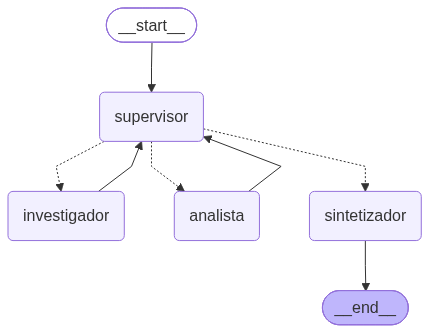

In [1]:
from IPython.display import Image, display

import config
from graph import app

# Diagrama del grafo, generado a partir del grafo compilado
display(Image(app.get_graph().draw_mermaid_png()))

In [2]:
def correr(estado_inicial):
    """Ejecuta el grafo e imprime lo que aporta cada nodo. Devuelve el estado final."""
    estado_final = None
    for paso in app.stream(estado_inicial, stream_mode="values"):
        estado_final = paso
        ultimo = paso["messages"][-1]
        print(f"===== {(ultimo.name or 'usuario').upper()} =====")
        print(ultimo.text)
        print()
    return estado_final


def resumen(estado):
    """Muestra el estado compartido: quién aportó qué y cuántos pasos se usaron."""
    for aporte in estado["aportes"]:
        print(f"[{aporte['agente']}] {aporte['instruccion'][:120]}...")
    print()
    print("Pasos del supervisor:", estado["pasos"])
    print("Tarea completa:", estado["task_completed"])

## 1. Flujo normal
La pregunta necesita dos especialistas: primero hay que **buscar** reseñas y precios (Investigador) y después **calcular** el sentimiento y la diferencia de precio (Analista).

In [3]:
pregunta = (
    "¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la "
    "competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio."
)
estado = correr({"messages": [("user", pregunta)]})

===== USUARIO =====
¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio.



09:14:59 [INFO] nodo supervisor -> investigador (3.63 s)


===== SUPERVISOR =====
-> investigador: Todavía no hay datos, así que el investigador debe obtener las reseñas y los precios antes de que el analista calcule el porcentaje de reseñas positivas y la diferencia de precio.



09:15:05 [INFO] nodo investigador (6.04 s)


===== INVESTIGADOR =====
## Reseñas de clientes: yerba mate de Supermercados del Valle

Se encontraron **5 reseñas en total**.

| # | Fuente | Texto completo | Calificación |
|---|--------|----------------|--------------|
| 1 | Google Maps | "La yerba de la marca propia es muy buena, rinde un montón y tiene buen sabor." | No disponible |
| 2 | Instagram | "Excelente yerba, la compro siempre. Recomendable." | No disponible |
| 3 | Google Maps | "Me pareció cara para lo que es, y el paquete vino roto." | No disponible |
| 4 | Facebook | "Buena yerba pero últimamente siempre falta en la góndola." | No disponible |
| 5 | Instagram | "Muy rica, suave y sin palo. Excelente relación precio calidad." | No disponible |

Las fuentes no traen calificación numérica ni en estrellas para ninguna reseña.

## Precios

| Fuente | Marca | Presentación | Gramaje | Precio |
|--------|-------|--------------|---------|--------|
| Supermercados del Valle (nuestro precio) | No disponible | No disponible | 1 k

...

===== ANALISTA =====
## Resultados

### 1) Sentimiento de las reseñas

| # | Clasificación | Criterio |
|---|---|---|
| 1 | Positiva | "muy buena", "rinde un montón", "buen sabor". |
| 2 | Positiva | "Excelente", "la compro siempre", "Recomendable". |
| 3 | Negativa | "cara" y "paquete roto". No hay ningún elemento positivo. |
| 4 | Positiva, con queja de stock | "Buena yerba" valora el producto. La queja es de disponibilidad en góndola. |
| 5 | Positiva | "Muy rica, suave y sin palo", "Excelente relación precio calidad". |

**Cómo clasifiqué la reseña mixta (#4):** la conté como positiva porque el juicio sobre el producto es favorable. La queja es logística (falta de stock) y no habla de la calidad. La dejé marcada como una alerta operativa.

**Porcentaje de reseñas positivas:**
- Positivas: 4 (#1, #2, #4, #5). Negativas: 1 (#3).
- 4 / 5 = **80 %**.

**Diferencia con la herramienta:** la herramienta de análisis clasificó la #4 como neutra (puntaje 0). Con ese criterio da 3 / 5 = **60 

09:15:30 [INFO] nodo supervisor -> FINISH (3.77 s)


===== SUPERVISOR =====
-> FINISH: El investigador aportó las 5 reseñas y los 4 precios, el analista calculó 80% de reseñas positivas (60% con criterio estricto) y +$66,67 (+1,61%) frente al promedio de la competencia con cálculos correctos, y los datos no disponibles quedaron aclarados sin contradicciones.



09:15:35 [INFO] nodo sintetizador (5.71 s)


===== SINTETIZADOR =====
## Resumen

**Opinión de los clientes:** 4 de 5 reseñas son positivas, es decir **80 %**. Elogian el sabor, el rendimiento y la relación precio-calidad. Si no se cuenta como positiva la reseña #4 ("Buena yerba pero siempre falta en la góndola"), el piso es **60 %** (3 de 5). Elegimos 80 % porque la queja es de stock y no de calidad.

**Precio de 1 kg frente a la competencia:**
- Nuestro precio: **$4.200**
- Promedio de la competencia: **$4.133,33**
- Diferencia: **+$66,67 (+1,61 %)**, o sea, estamos **levemente caros**.

| Competidor | Precio | Diferencia nuestra |
|---|---|---|
| SuperAhorro | $3.900 | +$300 (+7,69 %) |
| El Barrio | $4.000 | +$200 (+5,00 %) |
| MaxiCompra | $4.500 | −$300 (−6,67 %) |

Somos más caros que 2 de los 3 competidores, pero la diferencia con el promedio es chica.

**Puntos a atender:** el stock en góndola (reseña #4) y un paquete roto (reseña #3). Una sola reseña menciona el precio como caro.

**Limitaciones:**
- Son solo 5 reseñas 

In [4]:
resumen(estado)

[investigador] Buscá las reseñas de clientes sobre la yerba mate de Supermercados del Valle (texto completo y calificación de cada rese...
[analista] Con los datos siguientes, calculá: (1) el sentimiento de cada una de las 5 reseñas (positiva, negativa o mixta) a partir...

Pasos del supervisor: 3
Tarea completa: True


## 2. Refinamiento: el Supervisor detecta un error
Arrancamos el grafo con dos aportes ya cargados en el estado:

- uno **correcto** del Investigador (los datos reales de las fuentes),
- uno **con errores a propósito** del Analista: dice que el 100% de las reseñas son positivas y que estamos 20% más baratos, cosa que contradice los datos.

Según su rúbrica, el Supervisor no debería dar FINISH: tiene que mandar al Analista a corregir.

In [5]:
datos_investigador = (
    "Reseñas de la yerba: "
    "(1) 'La yerba de la marca propia es muy buena, rinde un montón y tiene buen sabor.' "
    "(2) 'Excelente yerba, la compro siempre. Recomendable.' "
    "(3) 'Me pareció cara para lo que es, y el paquete vino roto.' "
    "(4) 'Buena yerba pero últimamente siempre falta en la góndola.' "
    "(5) 'Muy rica, suave y sin palo. Excelente relación precio calidad.' "
    "Precios yerba 1 kg: Supermercados del Valle $4200, SuperAhorro $3900, "
    "MaxiCompra $4500, El Barrio $4000."
)

aportes_previos = [
    {"agente": "investigador", "instruccion": "Buscá reseñas y precios de la yerba.",
     "resultado": datos_investigador},
    {"agente": "analista", "instruccion": "Calculá sentimiento y diferencia de precio.",
     "resultado": "El 100% de las reseñas son positivas y estamos 20% más baratos que la competencia."},
]

estado = correr({"messages": [("user", pregunta)], "aportes": aportes_previos})

===== USUARIO =====
¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio.



09:15:42 [INFO] nodo supervisor -> analista (6.49 s)


===== SUPERVISOR =====
-> analista: El analista se contradice con los datos del investigador: la reseña 3 es negativa, así que no puede haber 100% positivas, y nuestro precio de $4200 supera el promedio de la competencia ($4133), así que tampoco estamos 20% más baratos.



09:15:51 [INFO] nodo analista (8.93 s)


===== ANALISTA =====
## (a) Sentimiento de las reseñas

| # | Reseña | Clasificación |
|---|---|---|
| 1 | Muy buena, rinde, buen sabor | Positiva |
| 2 | Excelente, la compro siempre | Positiva |
| 3 | Cara, paquete roto | Negativa |
| 4 | Buena, pero siempre falta en góndola | Mixta |
| 5 | Muy rica, excelente relación precio-calidad | Positiva |

La herramienta clasificó la reseña 4 como "neutro" (puntaje 0). Tiene un elogio y una queja, así que la tomo como mixta, que es lo que pediste.

- **Conteo:** 3 positivas, 1 negativa, 1 mixta (5 en total).
- **Porcentaje de positivas:** 3 / 5 = **60%**.

## (b) Precios de la yerba de 1 kg

**Promedio de la competencia:**
(3900 + 4500 + 4000) / 3 = 12.400 / 3 = **$4.133,33**

**Diferencia contra el promedio:**
(4200 − 4133,33) / 4133,33 = 66,67 / 4133,33 ≈ **+1,61%**

**Diferencia contra cada competidor:**

| Competidor | Precio | Cuenta | Diferencia |
|---|---|---|---|
| SuperAhorro | $3.900 | (4200 − 3900) / 3900 = 300 / 3900 | **+7,69%** 

09:15:57 [INFO] nodo supervisor -> FINISH (5.87 s)


===== SUPERVISOR =====
-> FINISH: El investigador trajo reseñas y precios, y el analista corrigió su primer error con cuentas verificables (60% de reseñas positivas y 1,61% más caros que el promedio de la competencia), así que se cumple toda la rúbrica.



09:16:02 [INFO] nodo sintetizador (5.70 s)


===== SINTETIZADOR =====
## Resumen

**Reseñas de la yerba: 60% positivas**
- De 5 reseñas, 3 son positivas, 1 es mixta (buena, pero falta en góndola) y 1 es negativa (cara y con el paquete roto).
- Las quejas se repiten en tres puntos: precio, paquete roto y faltante en góndola.

**Precio de la yerba de 1 kg: estamos apenas más caros**
- Nuestro precio es $4.200 y el promedio de la competencia es $4.133,33, así que estamos un **1,61% más caros**.

| Competidor | Precio | Diferencia nuestra |
|---|---|---|
| SuperAhorro | $3.900 | +7,69% (más caros) |
| El Barrio | $4.000 | +5,00% (más caros) |
| MaxiCompra | $4.500 | −6,67% (más baratos) |

**Aclaración:** el primer análisis, que hablaba de 100% de reseñas positivas y 20% más baratos, era incorrecto. Los valores de arriba son los correctos. Además, son solo 5 reseñas, así que el porcentaje es orientativo.

## Recomendación
No bajaría el precio, porque la diferencia es chica y la yerba tiene buena aceptación. Priorizaría reponer stock 

In [6]:
resumen(estado)

[investigador] Buscá reseñas y precios de la yerba....
[analista] Calculá sentimiento y diferencia de precio....
[analista] Rehacé el análisis con estos datos. Reseñas de la yerba: (1) 'La yerba de la marca propia es muy buena, rinde un montón ...

Pasos del supervisor: 2
Tarea completa: True


## 3. Corte por límite de pasos
Bajamos `MAX_PASOS` a 1 para simular un caso en el que el equipo no llega a terminar. Después de la primera decisión, el Supervisor corta sí o sí y pasa al Sintetizador, aunque falte el análisis.

In [7]:
config.MAX_PASOS = 1
try:
    estado = correr({"messages": [("user", pregunta)]})
finally:
    config.MAX_PASOS = 6  # volvemos al valor normal

===== USUARIO =====
¿Qué opinan los clientes de nuestra yerba y estamos caros o baratos frente a la competencia? Quiero el porcentaje de reseñas positivas y la diferencia de precio.



09:16:05 [INFO] nodo supervisor -> investigador (2.79 s)


===== SUPERVISOR =====
-> investigador: Todavía no hay datos; hace falta que el investigador reúna reseñas y precios antes de que el analista calcule el porcentaje de reseñas positivas y la diferencia de precio.



09:16:11 [INFO] nodo investigador (6.18 s)


09:16:11 [INFO] nodo supervisor -> FINISH (0.00 s)


===== INVESTIGADOR =====
## Reseñas de clientes: yerba mate de Supermercados del Valle

Se encontraron 5 reseñas. Las fuentes no incluyen calificaciones numéricas, solo texto.

| # | Fuente | Texto |
|---|--------|-------|
| 1 | Google Maps | "La yerba de la marca propia es muy buena, rinde un montón y tiene buen sabor." |
| 2 | Instagram | "Excelente yerba, la compro siempre. Recomendable." |
| 3 | Google Maps | "Me pareció cara para lo que es, y el paquete vino roto." |
| 4 | Facebook | "Buena yerba pero últimamente siempre falta en la góndola." |
| 5 | Instagram | "Muy rica, suave y sin palo. Excelente relación precio calidad." |

## Precios de yerba (presentación 1 kg)

| Fuente | Texto en la fuente |
|--------|--------------------|
| Supermercados del Valle (nuestro precio) | "Yerba 1 kg: $4200" |
| Competidor: SuperAhorro | "Yerba 1 kg: $3900" |
| Competidor: MaxiCompra | "Yerba 1 kg: $4500" |
| Competidor: El Barrio | "Yerba 1 kg: $4000" |

## Aclaraciones
- Las fuentes de preci

09:16:25 [INFO] nodo sintetizador (13.63 s)


===== SINTETIZADOR =====
## Resumen

**Opinión de los clientes**
- Se analizaron solo **5 reseñas**, sin calificaciones numéricas.
- **4 de 5 (80%) son positivas.** Incluye la reseña 4, que elogia la yerba pero se queja de que falta en góndola. Si esa se cuenta como mixta, baja a **3 de 5 (60%)**.
- **1 de 5 (20%) es negativa:** dice que es cara y que el paquete llegó roto.
- Se destacan el sabor, que rinde y que es suave y sin palo. Los puntos débiles son el faltante en góndola, el precio (en una reseña) y un paquete dañado.

**Precio frente a la competencia (1 kg)**

| Supermercado | Precio | Nuestra diferencia |
|---|---|---|
| Supermercados del Valle | $4.200 | — |
| SuperAhorro | $3.900 | +$300 (+7,7%) |
| El Barrio | $4.000 | +$200 (+5,0%) |
| MaxiCompra | $4.500 | −$300 (−6,7%) |

El promedio de la competencia es de unos $4.133, así que estamos **alrededor de $67 (1,6%) por encima**. Estamos en el medio: más caros que dos competidores y más baratos que uno.

**Limitaciones:** so

In [8]:
resumen(estado)

[investigador] Buscá las reseñas de clientes de la yerba mate de Supermercados del Valle (texto y/o calificación de cada reseña, con la...

Pasos del supervisor: 1
Tarea completa: True
